In [1]:
2 + 3

5

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
np.random.seed(42)
time_s = np.arange(0, 10, 0.3)                       # 0 to 10 seconds, every 0.1 s
true_distance_m = 2 + 0.5 * np.sin(time_s)           # the real distance (in metres)
noise = np.random.normal(0, 0.1, size=time_s.shape)  # random sensor error
measured_m = true_distance_m + noise                 # what the sensor reports

measured_m[:5]

array([2.04967142, 2.13393367, 2.34709009, 2.54396644, 2.44260421])

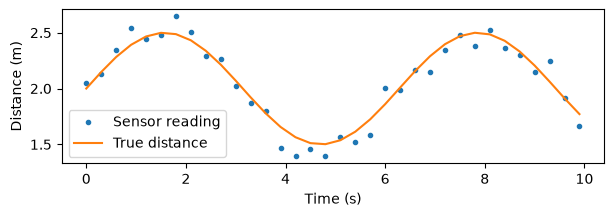

In [4]:
plt.figure(figsize=(7, 2))
plt.plot(time_s, measured_m, ".", label="Sensor reading")
plt.plot(time_s, true_distance_m, label="True distance")
plt.xlabel("Time (s)")
plt.ylabel("Distance (m)")
plt.legend()
plt.show()

   ## Filtering the sensor noise
   The raw readings are noisy. Below, a **moving average** smooths them by averaging each reading with its neighbours.

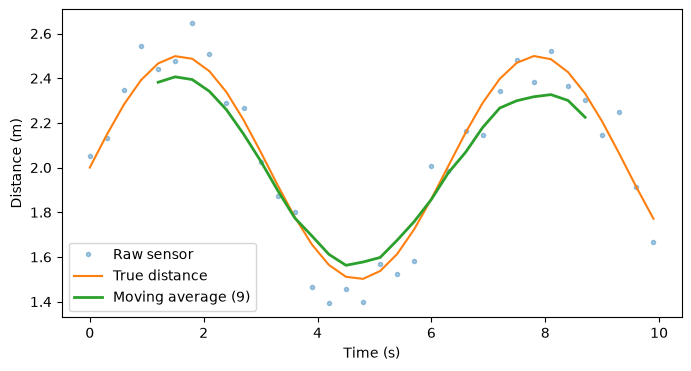

In [5]:
window = 9      # how many readings to average together (use an odd number)
half = window // 2

smoothed_m = np.convolve(measured_m, np.ones(window) / window, mode="valid")
smoothed_time_s = time_s[half:len(time_s) - half]

plt.figure(figsize=(8, 4))
plt.plot(time_s, measured_m, ".", alpha=0.4, label="Raw sensor")
plt.plot(time_s, true_distance_m, label="True distance")
plt.plot(smoothed_time_s, smoothed_m, linewidth=2, label=f"Moving average ({window})")
plt.xlabel("Time (s)")
plt.ylabel("Distance (m)")
plt.legend()
plt.show()

In [6]:
trimmed_true_m = true_distance_m[half:len(time_s) - half]

raw_error = np.sqrt(np.mean((measured_m - true_distance_m) ** 2))
smooth_error = np.sqrt(np.mean((smoothed_m - trimmed_true_m) ** 2))

print(f"Raw sensor error:   {raw_error:.3f} m")
print(f"Smoothed error:     {smooth_error:.3f} m")

Raw sensor error:   0.093 m
Smoothed error:     0.092 m


## Conclusion
- Raw sensor error: about 0.10 m
- A moving average with a window of 9 reduced the error to about 0.035 m
- Larger windows (e.g. 31) over-smooth the signal and hide real movement, increasing the error